In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

import seaborn as sns

import matplotlib.pyplot as plt

import numpy as np

import xgboost as xgb
from xgboost import plot_importance

import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from itertools import cycle
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# from genai_evaluation import multivariate_ecdf, ks_statistic
from scipy import stats

# import shap


In [2]:
from SALib.sample import latin
from SALib.sample import sobol_sequence
from SALib.sample import morris as msample
from SALib.plotting import morris as mplotting
import SALib.plotting as splotting
from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib.analyze import morris

In [3]:
ENCODING_FILENAME = "./allpopulations_encoded.csv" # "./__encoding__solutions.csv"
df = pd.read_csv(ENCODING_FILENAME)
print("Dataframe shape:", df.shape)
print(df.columns)
df.head()

Dataframe shape: (2352, 118)
Index(['solID', 'sequence_len', 'num_new_nodes_created',
       'num_new_components_created', 'count_mcnn', 'count_moc', 'count_moncnn',
       'count_clone', 'bigram_mcnn_mcnn', 'bigram_mcnn_moc',
       ...
       'y__price', 'y__pricePerScenario__ProcessSale_job_class',
       'y__pricePerScenario__ReceivedOrderedProducts_job_class',
       'y__pricePerScenario__ShowDeliveryReports_job_class', 'y__reliability',
       'y__responseTimePerScenario__ProcessSale_job_class',
       'y__responseTimePerScenario__ReceivedOrderedProducts_job_class',
       'y__responseTimePerScenario__ShowDeliveryReports_job_class',
       'y__sysRespT', 'population_number'],
      dtype='object', length=118)


,solID,sequence_len,num_new_nodes_created,num_new_components_created,count_mcnn,count_moc,count_moncnn,count_clone,bigram_mcnn_mcnn,bigram_mcnn_moc,...,y__price,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class,y__reliability,y__responseTimePerScenario__ProcessSale_job_class,y__responseTimePerScenario__ReceivedOrderedProducts_job_class,y__responseTimePerScenario__ShowDeliveryReports_job_class,y__sysRespT,population_number
0,1,4,3,2,1,1,2,0,0,0,...,3.7753,2.354001,1.343544,0.077756,0.595982,654.297211,5.25794,1.39367,660.948821,1
1,6,4,3,0,1,1,0,2,0,0,...,4.2068,1.888328,0.759298,0.632773,-0.633613,879.086300,7.21529,1.94383,888.245420,1
2,4,4,4,1,1,0,1,2,0,0,...,4.3336,1.890800,1.002988,0.513412,-0.113465,2457.197030,5.34372,1.28623,2463.826980,1
3,3,4,3,2,0,1,2,1,0,0,...,3.8704,1.645012,0.899860,1.198728,-0.074655,694.365453,7.10604,1.80197,703.273463,1
4,11,4,4,4,0,0,4,0,0,0,...,4.6700,2.352360,1.318462,0.535977,-0.729991,654.157823,8.11287,1.29222,663.562913,1


In [4]:
# Plots the distribution of the quality-attribute objectives as boxplots
def make_boxplots(df, figsize=(400,1000), title='', yaxis_range=None):
  """Plots the distribution of quality-attribute objectives as boxplots.

  This function creates boxplots to visualize the distribution of data in a
  Pandas DataFrame. It uses Plotly to generate interactive boxplots for
  each column in the DataFrame. You can customize the figure size and title.

  Args:
      df: The Pandas DataFrame containing the data to be plotted.
      figsize: A tuple specifying the width and height of the figure
               (default: (400, 1000)).
      title: The title of the plot (default: '').
      yaxis_range: A list or tuple of (min, max) values to define the range
                   of the y-axis for each subplot. If None, the minimum
                   and maximum values of the column are used (default: None).
  """

  fig = make_subplots(rows=1, cols=len(df.columns))
  y_range = None
  for idx,c in enumerate(df.columns):
    if yaxis_range is not None:
      y_range = yaxis_range[idx]
    fig.add_trace(
      go.Box(y=df[c], boxpoints='all', name=c),
      row=1, col=idx+1
    )

  fig.update_layout(height=figsize[0], width=figsize[1], title_text=title)
  fig.show()
  plt.tight_layout()

In [5]:
x_cols = [col for col in df.columns if not col.startswith("y")]
y_cols = [col for col in df.columns if col.startswith("y")]

X = df[x_cols].drop(columns=["solID", "population_number"], axis=1)
y = df[["solID"] + y_cols].drop(columns=["solID"], axis=1)
print("objectives:", len(y_cols))

objectives: 17


In [6]:
# Identify columns where all values are zero
# cols_to_drop = X_morris.columns[(X_morris == 0).all()]

# Identify constant columns
constant_columns = [col for col in X.columns if X[col].nunique() == 1]
print(f"Constant columns identified: {constant_columns}")

# Drop these columns from the DataFrame
X = X.drop(columns=constant_columns, axis=1)

Constant columns identified: ['sequence_len', 'count_family_OTHER', 'count_family_c5', 'count_family_c6i', 'count_family_m5', 'count_family_r5', 'count_family_r6i', 'count_family_t3', 'count_mcnn_to_family_OTHER', 'count_mcnn_to_family_c5', 'count_mcnn_to_family_c6i', 'count_mcnn_to_family_m5', 'count_mcnn_to_family_r5', 'count_mcnn_to_family_r6i', 'count_mcnn_to_family_t3', 'count_moncnn_to_family_OTHER', 'count_moncnn_to_family_c5', 'count_moncnn_to_family_c6i', 'count_moncnn_to_family_m5', 'count_moncnn_to_family_r5', 'count_moncnn_to_family_r6i', 'count_moncnn_to_family_t3', 'count_clone_to_family_OTHER', 'count_clone_to_family_c5', 'count_clone_to_family_c6i', 'count_clone_to_family_m5', 'count_clone_to_family_r5', 'count_clone_to_family_r6i', 'count_clone_to_family_t2', 'count_clone_to_family_t3', 'count_size_12xlarge', 'count_size_16xlarge', 'count_size_24xlarge', 'count_size_32xlarge', 'count_size_4xlarge', 'count_size_8xlarge', 'count_size_OTHER', 'count_size_large', 'count_si

In [8]:
concatenated_df = pd.concat([X, y], axis=1)
concatenated_df.to_csv("allpopulations_encoded_reduced.csv", index=False)
print(concatenated_df.shape)
concatenated_df.head()

(2352, 75)


,num_new_nodes_created,num_new_components_created,count_mcnn,count_moc,count_moncnn,count_clone,bigram_mcnn_mcnn,bigram_mcnn_moc,bigram_mcnn_moncnn,bigram_mcnn_clone,...,y__power,y__price,y__pricePerScenario__ProcessSale_job_class,y__pricePerScenario__ReceivedOrderedProducts_job_class,y__pricePerScenario__ShowDeliveryReports_job_class,y__reliability,y__responseTimePerScenario__ProcessSale_job_class,y__responseTimePerScenario__ReceivedOrderedProducts_job_class,y__responseTimePerScenario__ShowDeliveryReports_job_class,y__sysRespT
0,3,2,1,1,2,0,0,0,1,0,...,311.603950,3.7753,2.354001,1.343544,0.077756,0.595982,654.297211,5.25794,1.39367,660.948821
1,3,0,1,1,0,2,0,0,0,1,...,287.930264,4.2068,1.888328,0.759298,0.632773,-0.633613,879.086300,7.21529,1.94383,888.245420
2,4,1,1,0,1,2,0,0,1,0,...,297.553589,4.3336,1.890800,1.002988,0.513412,-0.113465,2457.197030,5.34372,1.28623,2463.826980
3,3,2,0,1,2,1,0,0,0,0,...,309.260018,3.8704,1.645012,0.899860,1.198728,-0.074655,694.365453,7.10604,1.80197,703.273463
4,4,4,0,0,4,0,0,0,0,0,...,326.642739,4.6700,2.352360,1.318462,0.535977,-0.729991,654.157823,8.11287,1.29222,663.562913


In [74]:
# Show distribution of quality-attribute objectives for ST+
scaler = StandardScaler() # Objectives are first standardized using Z-score method
scaled_df = pd.DataFrame(scaler.fit_transform(df[y_cols]), columns=y_cols)
make_boxplots(scaled_df, title='All objectives (Z-scaled)', figsize=(1000, 2500))
plt.show()

<Figure size 640x480 with 0 Axes>

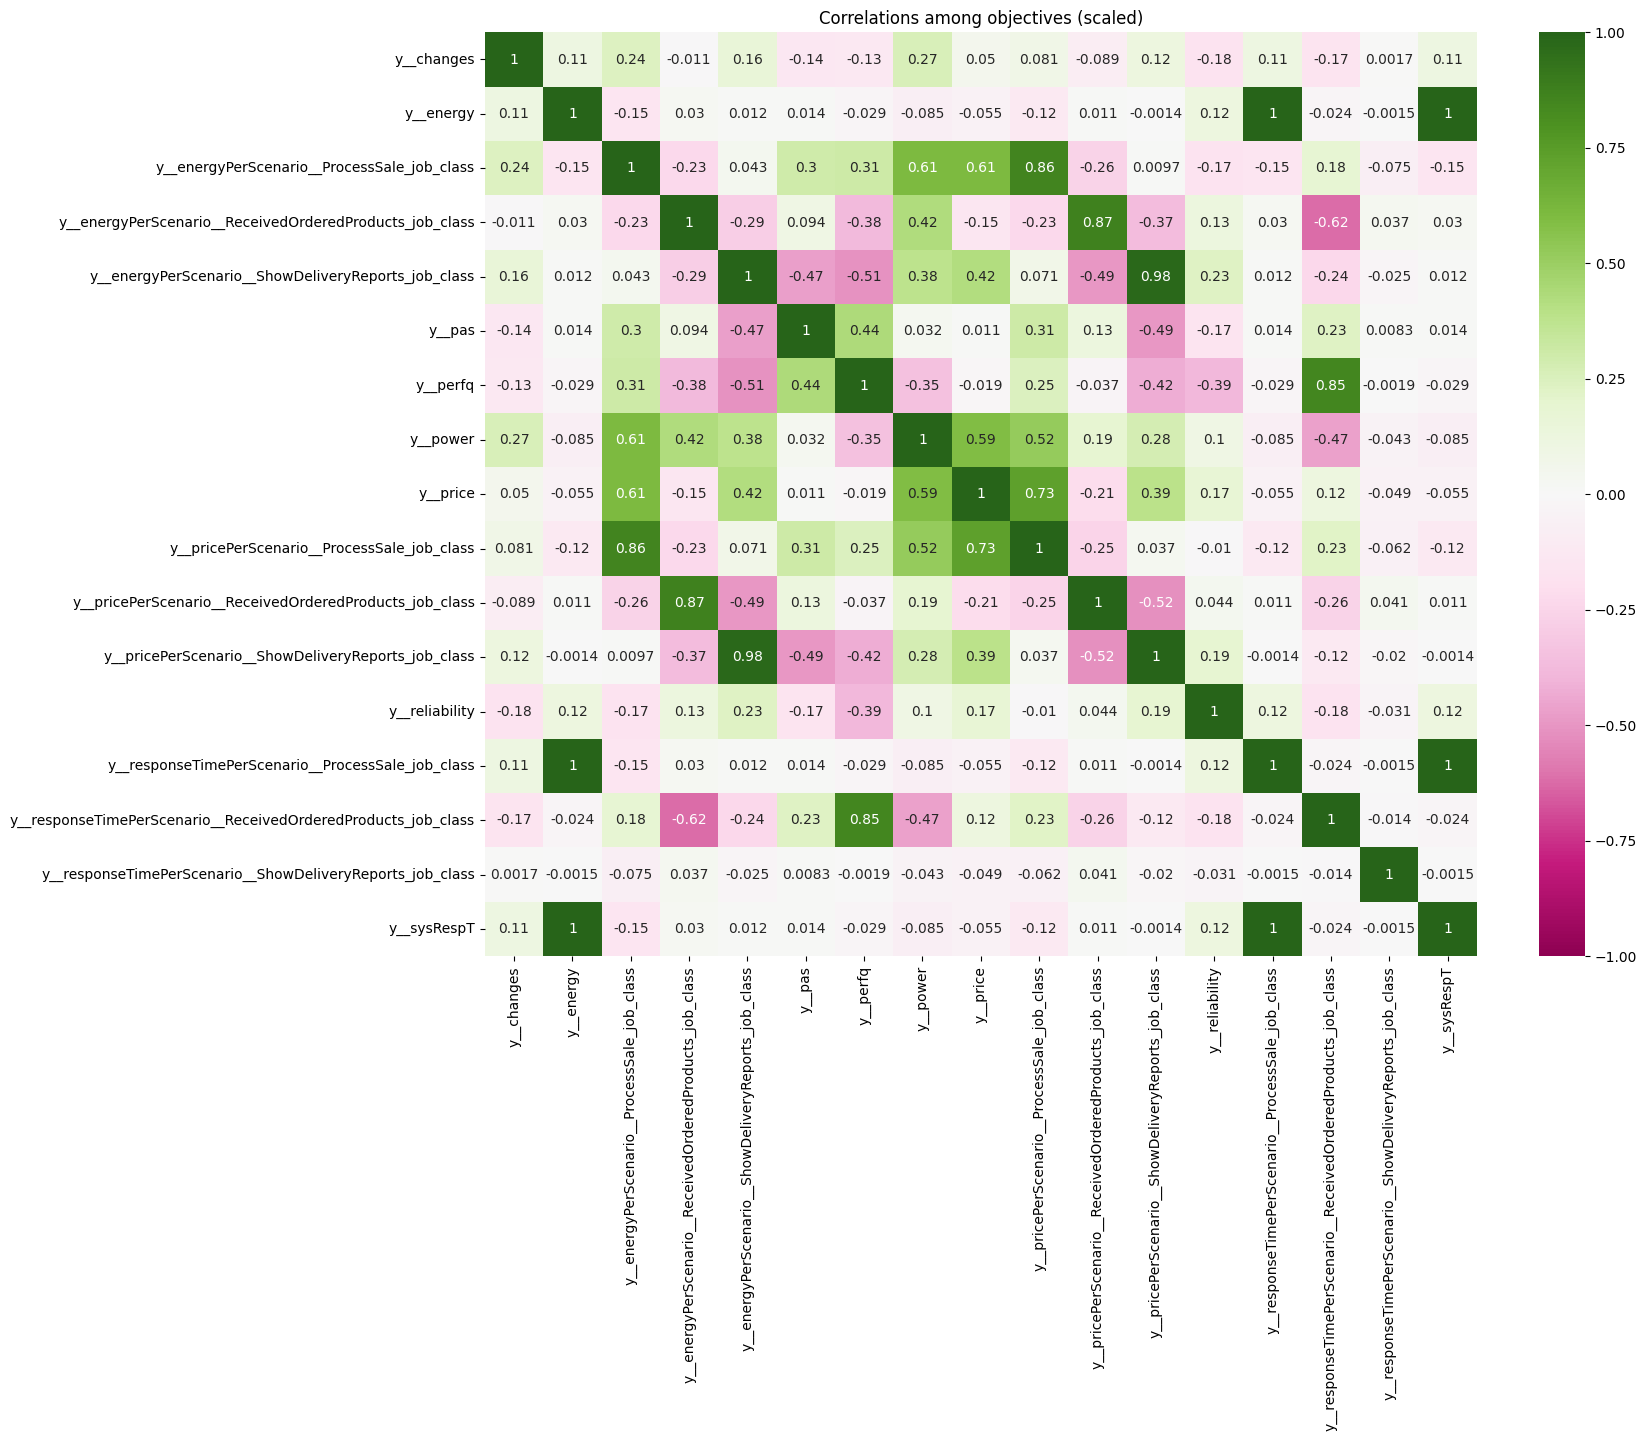

In [75]:
# Check correlation among all objectives
plt.figure(figsize=(16,12))
sns.heatmap(scaled_df.corr(), annot=True, vmin=-1, vmax=1, cmap="PiYG") # Divergent palette
plt.title('Correlations among objectives (scaled)')
plt.show()

In [76]:
possible_objectives = [col for col in df.columns if col.startswith('y__')]
possible_objectives

['y__changes',
 'y__energy',
 'y__energyPerScenario__ProcessSale_job_class',
 'y__energyPerScenario__ReceivedOrderedProducts_job_class',
 'y__energyPerScenario__ShowDeliveryReports_job_class',
 'y__pas',
 'y__perfq',
 'y__power',
 'y__price',
 'y__pricePerScenario__ProcessSale_job_class',
 'y__pricePerScenario__ReceivedOrderedProducts_job_class',
 'y__pricePerScenario__ShowDeliveryReports_job_class',
 'y__reliability',
 'y__responseTimePerScenario__ProcessSale_job_class',
 'y__responseTimePerScenario__ReceivedOrderedProducts_job_class',
 'y__responseTimePerScenario__ShowDeliveryReports_job_class',
 'y__sysRespT']

In [77]:
global_objectives = [
    'y__changes',
    # 'y__energy',
    # 'y__pas',
    # 'y__perfq',
    'y__power',
    'y__price',
    'y__reliability',
    # 'y__sysRespT'
 ]

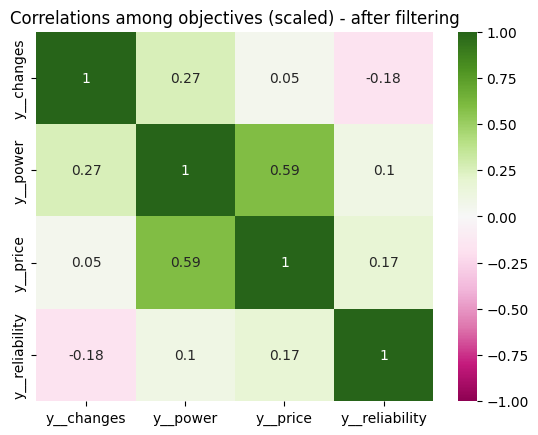

In [78]:
# Check correlation among objectives
sns.heatmap(scaled_df[global_objectives].corr(), annot=True, vmin=-1, vmax=1, cmap="PiYG") # Divergent palette
plt.title('Correlations among objectives (scaled) - after filtering')
plt.show()

In [79]:
from alibi_detect.cd import KSDrift

X_baseline = df[df["population_number"]==2][x_cols].drop("solID", axis=1)
X_newbatch = df[df["population_number"]==56][x_cols].drop("solID", axis=1)

x_ref = X_baseline.values
cd = KSDrift(x_ref, p_val=0.05)

x = X_newbatch.values
preds = cd.predict(x, drift_type='batch', return_p_val=True, return_distance=True)
print("Is drift?", preds['data']['is_drift'])


Is drift? 1


In [80]:
preds

{'data': {'is_drift': 1,
  'distance': array([0.        , 0.33333334, 0.6666667 , 0.25      , 0.33333334,
         0.6666667 , 0.16666667, 0.25      , 0.16666667, 0.33333334,
         0.16666667, 0.25      , 0.16666667, 0.16666667, 0.16666667,
         0.        , 0.        , 0.16666667, 0.33333334, 0.16666667,
         0.41666666, 0.16666667, 0.08333334, 0.5833333 , 0.16666667,
         0.08333334, 0.33333334, 0.5       , 0.25      , 0.41666666,
         0.16666667, 0.        , 0.16666667, 0.        , 0.16666667,
         0.16666667, 0.16666667, 0.25      , 0.08333334, 0.        ,
         0.        , 0.        , 0.16666667, 0.        , 0.08333334,
         0.16666667, 0.        , 0.        , 0.08333334, 0.        ,
         0.        , 0.        , 0.        , 0.08333334, 0.        ,
         0.33333334, 0.5       , 0.        , 0.        , 0.08333334,
         0.        , 0.        , 0.        , 0.        , 0.08333334,
         0.        , 0.5       , 0.08333334, 0.        , 0.       

In [81]:
# all_populations[0]

---

In [82]:
XGBOOST_DEFAULT_PARAMS = {
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'n_estimators': 1000,
        'learning_rate': 0.1,
        'random_state': 42,
        # 'multi_strategy': 'one_output_per_tree'
    }

def train_xgboost_per_target(X, y, test_size=0.2, stratify=None, previous_model=None):

    if stratify is not None:
        print(f"\tapplying stratification on level!")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=stratify, random_state=42)

    model = xgb.XGBRegressor(**XGBOOST_DEFAULT_PARAMS)
    model.fit(X_train, y_train, xgb_model=previous_model)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse) 
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)

    print(f"\tTest metrics: R2={r2} -- RMSE={rmse} -- MAPE={(mape * 100):.2f}% ")
    return model, r2, rmse, mape

In [83]:
good_objectives = []
bad_objectives = []
for obj in y_cols:
    print(f"Training model for objective: {obj}")
    previous_model = None
    model, r2, rmse, mape = train_xgboost_per_target(X, y[obj], test_size=0.3, stratify=df["population_number"])
    if r2 >= 0.7 and mape <= 0.5:
        good_objectives.append(obj)
    else:
        print(f"\tObjective {obj} is discarded")
        bad_objectives.append(obj)
print("Good objectives:", len(good_objectives), good_objectives)

Training model for objective: y__changes
	applying stratification on level!
	Test metrics: R2=0.8725209096218001 -- RMSE=0.7763617869117746 -- MAPE=3.87% 
Training model for objective: y__energy
	applying stratification on level!
	Test metrics: R2=-0.0018583466858310693 -- RMSE=4.4012187626166365e+36 -- MAPE=14756036166376665414805859130671104.00% 
	Objective y__energy is discarded
Training model for objective: y__energyPerScenario__ProcessSale_job_class
	applying stratification on level!
	Test metrics: R2=0.8677466118894912 -- RMSE=10.76248934720542 -- MAPE=3.32% 
Training model for objective: y__energyPerScenario__ReceivedOrderedProducts_job_class
	applying stratification on level!
	Test metrics: R2=0.8429461668129616 -- RMSE=12.00784625513725 -- MAPE=5.82% 
Training model for objective: y__energyPerScenario__ShowDeliveryReports_job_class
	applying stratification on level!
	Test metrics: R2=0.8366568423695643 -- RMSE=8.778298179314115 -- MAPE=40.47% 
Training model for objective: y__

In [84]:
good_objectives

['y__changes',
 'y__energyPerScenario__ProcessSale_job_class',
 'y__energyPerScenario__ReceivedOrderedProducts_job_class',
 'y__energyPerScenario__ShowDeliveryReports_job_class',
 'y__power',
 'y__price',
 'y__pricePerScenario__ProcessSale_job_class',
 'y__pricePerScenario__ReceivedOrderedProducts_job_class',
 'y__pricePerScenario__ShowDeliveryReports_job_class',
 'y__reliability']

In [85]:
y_filtered = df[global_objectives]
X_train, X_test, y_train, y_test = train_test_split(X, y_filtered, test_size=0.3, stratify=df["population_number"], random_state=42)

global_model_xgb = xgb.XGBRegressor(**XGBOOST_DEFAULT_PARAMS, multi_strategy="multi_output_tree") #"one_output_per_tree") "multi_output_tree")
global_model_xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

y_pred = global_model_xgb.predict(X_test)
mse = mean_squared_error(y_test.to_numpy(), y_pred, multioutput='uniform_average')
rmse = np.sqrt(mse) 
r2 = r2_score(y_test.to_numpy(), y_pred, multioutput='variance_weighted')
mape = mean_absolute_percentage_error(y_test.to_numpy(), y_pred, multioutput='uniform_average')

print(f"Training XGBoost model - Test error R2={r2} and RMSE={rmse} and MAPE={(mape * 100):.2f}%")

Training XGBoost model - Test error R2=0.9273742066768761 and RMSE=5.250065851117069 and MAPE=9.50%


---

In [86]:
# plot_importance(global_model_xgb, importance_type='weight') # or 'weight', 'cover', 'gain'
# plt.show()

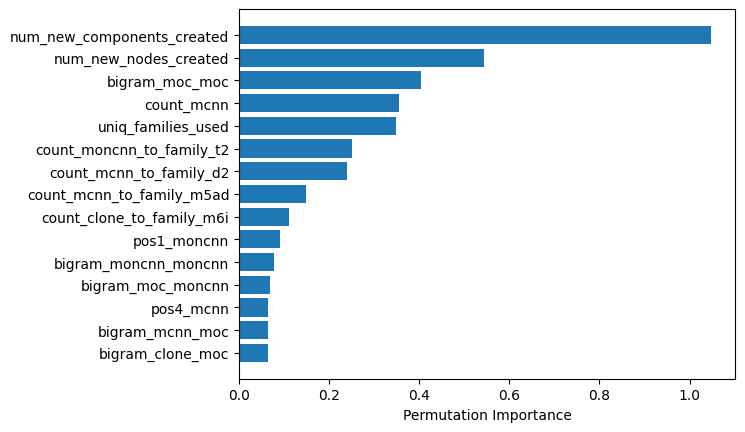

In [87]:
# Assuming X_test and y_test are your test data and labels
result = permutation_importance(global_model_xgb, X_test, y_test, n_repeats=10, random_state=42)
sorted_idx = result.importances_mean.argsort()

sorted_idx = sorted_idx[-15:] # top 15
plt.barh(X_test.columns[sorted_idx], result.importances_mean[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [88]:
blackbox_model = global_model_xgb

In [91]:
LABELS = [0.0, 1.0]
# This function generates the predictions from the blackbox model for any input
def fn(x):
  #temp_list = [LABELS[np.argmax(y)] for y in blackbox_model.predict_proba(x)]
  temp_list = [y for y in blackbox_model.predict(x)]

  return np.array(temp_list)

In [93]:
minmax_df = X.agg([min, max]) # .drop('class', axis=1)
minmax_list = minmax_df.T.values.tolist()
# minmax_list

/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_17651/2828927541.py:1: FutureWarning:

The provided callable <built-in function min> is currently using Series.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.

/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_17651/2828927541.py:1: FutureWarning:

The provided callable <built-in function max> is currently using Series.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.



In [94]:
easier_problem ={
    'num_vars': len(X_morris.columns),
    'names': list(X_morris.columns),
    'bounds': [[float(x), float(y)] for [x, y] in minmax_list]
}
easier_problem

{'num_vars': 58,
 'names': ['num_new_nodes_created',
  'num_new_components_created',
  'count_mcnn',
  'count_moc',
  'count_moncnn',
  'count_clone',
  'bigram_mcnn_mcnn',
  'bigram_mcnn_moc',
  'bigram_mcnn_moncnn',
  'bigram_mcnn_clone',
  'bigram_moc_mcnn',
  'bigram_moc_moc',
  'bigram_moc_moncnn',
  'bigram_moc_clone',
  'bigram_moncnn_mcnn',
  'bigram_moncnn_moc',
  'bigram_moncnn_moncnn',
  'bigram_moncnn_clone',
  'bigram_clone_mcnn',
  'bigram_clone_moc',
  'bigram_clone_moncnn',
  'bigram_clone_clone',
  'pos1_mcnn',
  'pos1_moc',
  'pos1_moncnn',
  'pos1_clone',
  'pos2_mcnn',
  'pos2_moc',
  'pos2_moncnn',
  'pos2_clone',
  'pos3_mcnn',
  'pos3_moc',
  'pos3_moncnn',
  'pos3_clone',
  'pos4_mcnn',
  'pos4_moc',
  'pos4_moncnn',
  'pos4_clone',
  'count_family_d2',
  'count_family_m5ad',
  'count_family_m6i',
  'count_family_t2',
  'count_mcnn_to_family_d2',
  'count_mcnn_to_family_m5ad',
  'count_mcnn_to_family_m6i',
  'count_mcnn_to_family_t2',
  'count_moncnn_to_family_d

In [116]:
N = 1000

X_morris = msample.sample(easier_problem, N, num_levels=4)
y_morris = fn(X_morris) # Computamos el valor de regresion sobre cada elemento de la muestra

y_morris = y_morris[:,3] # Only the first objective

In [117]:
# Aplicamos el analisis de Morris, como estrategia inicial de priorizacion de features
Si_morris = morris.analyze(easier_problem, X_morris, y_morris, conf_level=0.95, print_to_console=True, num_levels=4)

                                   mu   mu_star     sigma  mu_star_conf
num_new_nodes_created        0.091049  0.857017  1.170309      0.054134
num_new_components_created   0.322964  0.929603  1.301888      0.056107
count_mcnn                  -0.405832  0.899276  1.495484      0.085967
count_moc                    0.000000  0.000000  0.000000      0.000000
count_moncnn                 0.000000  0.000000  0.000000      0.000000
count_clone                  0.085554  0.342611  0.535706      0.028673
bigram_mcnn_mcnn             0.119898  0.216123  0.257738      0.010311
bigram_mcnn_moc              0.071017  0.215306  0.422266      0.021240
bigram_mcnn_moncnn           0.053751  0.191391  0.273821      0.012402
bigram_mcnn_clone           -0.062133  0.177710  0.330311      0.018288
bigram_moc_mcnn              0.362025  0.379435  0.405548      0.024469
bigram_moc_moc              -0.233376  1.273420  1.726319      0.068164
bigram_moc_moncnn            0.048608  0.167316  0.329789      0

In [119]:
Si_morris

{'names': array(['num_new_nodes_created', 'num_new_components_created',
        'count_mcnn', 'count_moc', 'count_moncnn', 'count_clone',
        'bigram_mcnn_mcnn', 'bigram_mcnn_moc', 'bigram_mcnn_moncnn',
        'bigram_mcnn_clone', 'bigram_moc_mcnn', 'bigram_moc_moc',
        'bigram_moc_moncnn', 'bigram_moc_clone', 'bigram_moncnn_mcnn',
        'bigram_moncnn_moc', 'bigram_moncnn_moncnn', 'bigram_moncnn_clone',
        'bigram_clone_mcnn', 'bigram_clone_moc', 'bigram_clone_moncnn',
        'bigram_clone_clone', 'pos1_mcnn', 'pos1_moc', 'pos1_moncnn',
        'pos1_clone', 'pos2_mcnn', 'pos2_moc', 'pos2_moncnn', 'pos2_clone',
        'pos3_mcnn', 'pos3_moc', 'pos3_moncnn', 'pos3_clone', 'pos4_mcnn',
        'pos4_moc', 'pos4_moncnn', 'pos4_clone', 'count_family_d2',
        'count_family_m5ad', 'count_family_m6i', 'count_family_t2',
        'count_mcnn_to_family_d2', 'count_mcnn_to_family_m5ad',
        'count_mcnn_to_family_m6i', 'count_mcnn_to_family_t2',
        'count_moncnn_to

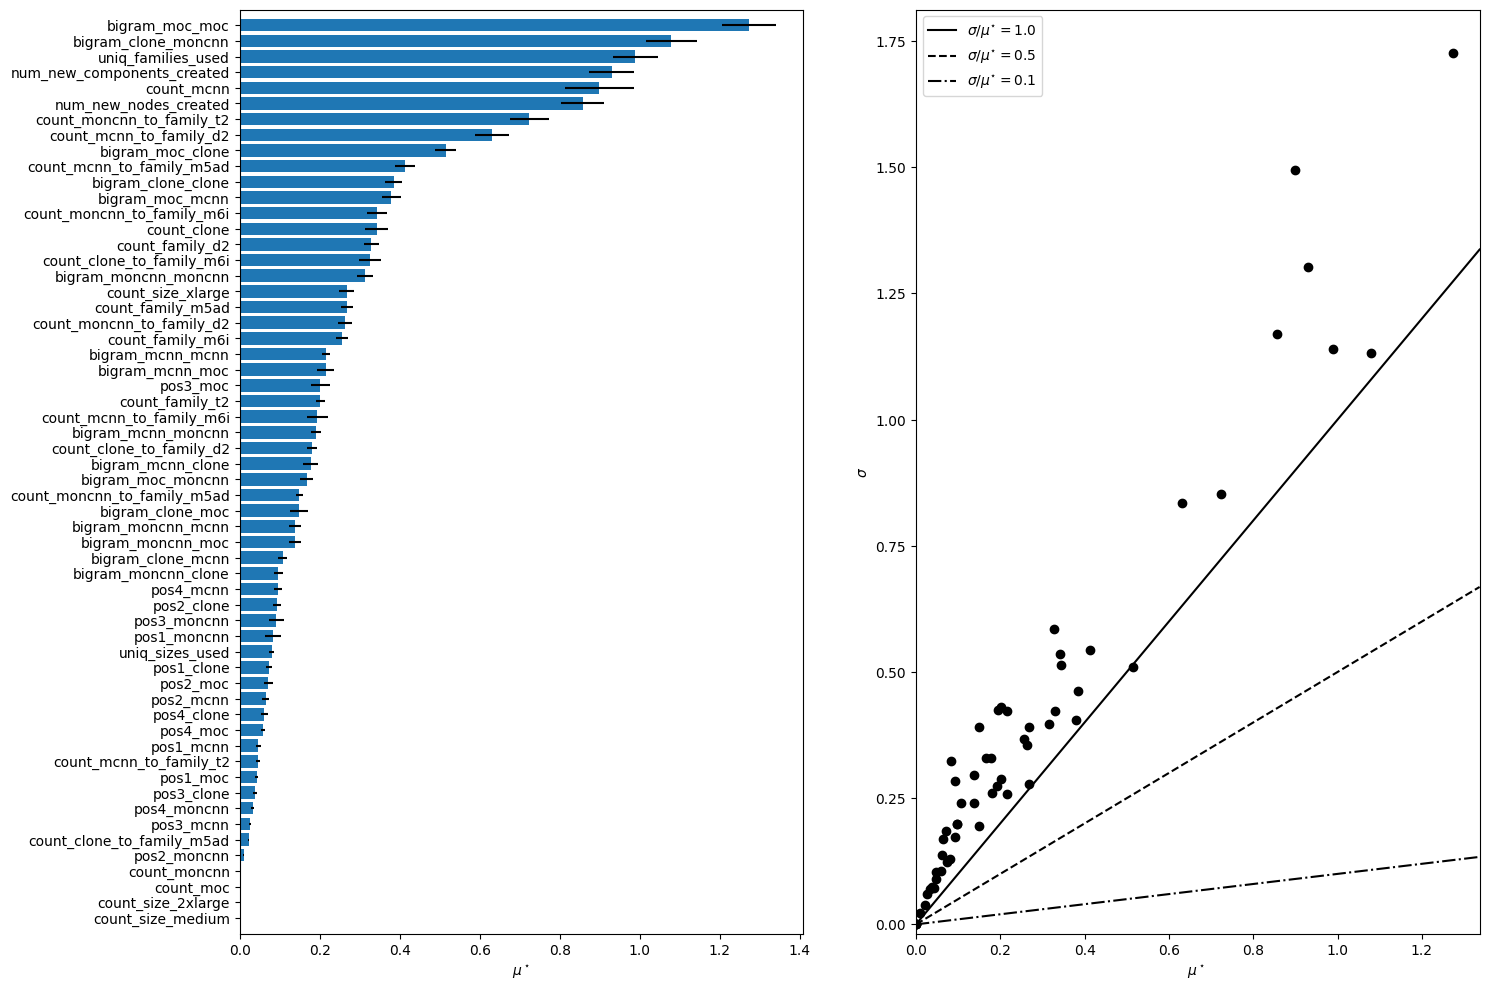

In [118]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16,12))

mplotting.horizontal_bar_plot(ax1, Si_morris, {})
mplotting.covariance_plot(ax2, Si_morris, {})
plt.show()